# Adversarial Search: Playing Dots and Boxes


## Instructions

Total Points: Undegraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play the game Dots and Boxes:

> "Dots and Boxes is a pencil-and-paper game for two players. The game starts with an empty grid of dots. Usually two players take turns adding a single horizontal or vertical line between two unjoined adjacent dots. A player who completes the fourth side of a 1x1 box earns one point and takes another turn. A point is typically recorded by placing a mark that identifies the player in the box, such as an initial. The game ends when no more lines can be placed. The winner is the player with the most points. The board may be of any size grid." (see [Dots and Boxes on Wikipedia](https://en.wikipedia.org/wiki/Dots_and_Boxes))

You can play Dots and Boxes [here](https://www.math.ucla.edu/~tom/Games/dots&boxes.html).

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

In [1]:
# Định nghĩa bài toán tìm kiếm đối kháng trong Dots and Boxes:
# 1. Initial State (Trạng thái khởi đầu): Lưới R x C chấm tròn (tạo thành (R-1)x(C-1) ô vuông). Chưa có cạnh nào được nối, chưa ai có điểm.
# 2. Actions(s): Tập các đoạn thẳng chưa được vẽ: (orientation, row, col) với orientation in ['h', 'v'].
# 3. Transition Model Result(s, player, a): Thêm cạnh a vào tập cạnh. Nếu cạnh a hoàn thành cạnh thứ 4 của 1 hoặc 2 ô vuông,
#    người chơi nhận điểm cho ô đó và ĐƯỢC ĐI TIẾP (extra turn). Nếu không hoàn thành ô nào, lượt chuyển cho đối thủ.
# 4. Terminal Test Terminal(s): Trạng thái kết thúc khi tất cả (R-1)x(C-1) ô vuông đã được người chơi chiếm giữ (hoặc vẽ hết cạnh).
# 5. Utility(s, player): Điểm thực nhận = (Số ô của player - Số ô của opponent), hoặc +1 / -1 / 0.

import dots_and_boxes as db
b0 = db.empty_board(size=(3, 3))
print('Trạng thái khởi đầu lưới 3x3 chấm (2x2 ô vuông):', b0)
print('Số cạnh khả dĩ ban đầu:', len(db.actions(b0)))

Trạng thái khởi đầu lưới 3x3 chấm (2x2 ô vuông): {'size': (3, 3), 'lines': {}, 'boxes': {}}
Số cạnh khả dĩ ban đầu: 12


How big is the state space? Give an estimate and explain it.

In [2]:
# Tính toán kích thước không gian trạng thái Dots and Boxes:
# Với lưới R x C chấm tròn:
# - Số cạnh ngang H = R * (C - 1)
# - Số cạnh dọc V = (R - 1) * C
# - Tổng số cạnh L = H + V
# - Số ô vuông B = (R - 1) * (C - 1)
# Mỗi cạnh có 2 trạng thái: Đã vẽ (True) hoặc Chưa vẽ (False) -> 2^L trạng thái cạnh.
# Mỗi ô vuông đã hoàn thành thuộc về Player 1 hoặc Player -1 -> 3^B trạng thái sở hữu ô.
# Giới hạn trên không gian trạng thái: S ≤ 2^L * 3^B.

def state_space_size(R, C):
    L = R * (C - 1) + (R - 1) * C
    B = (R - 1) * (C - 1)
    return L, B, (2 ** L) * (3 ** B)

for size in [(2, 2), (3, 3), (4, 4), (5, 5)]:
    L, B, S = state_space_size(*size)
    print(f'Lưới {size[0]}x{size[1]} chấm ({B} ô): L={L} cạnh -> Kích thước không gian trạng thái ≈ {S:.3e}')

Lưới 2x2 chấm (1 ô): L=4 cạnh -> Kích thước không gian trạng thái ≈ 4.800e+01
Lưới 3x3 chấm (4 ô): L=12 cạnh -> Kích thước không gian trạng thái ≈ 3.318e+05
Lưới 4x4 chấm (9 ô): L=24 cạnh -> Kích thước không gian trạng thái ≈ 3.302e+11
Lưới 5x5 chấm (16 ô): L=40 cạnh -> Kích thước không gian trạng thái ≈ 4.733e+19


How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [3]:
# Kích thước cây trò chơi (Game Tree Size):
# Bất kỳ ván đấu nào cũng kết thúc sau đúng L nước đi (với L là tổng số cạnh).
# Nếu không có luật đi tiếp (extra turn), số đường đi trong cây trò chơi tối đa là L!.
# Với luật đi tiếp, thứ tự hoàn thành ô làm phân nhánh có thể thay đổi người chơi nhưng tổng số nước đi tối đa vẫn là L.
import math
for size in [(2, 2), (3, 3), (4, 4), (5, 5)]:
    L = size[0] * (size[1] - 1) + (size[0] - 1) * size[1]
    print(f'Lưới {size[0]}x{size[1]}: L = {L} -> Số lá cây trò chơi tối đa (L!): {math.factorial(L):.3e}')

Lưới 2x2: L = 4 -> Số lá cây trò chơi tối đa (L!): 2.400e+01
Lưới 3x3: L = 12 -> Số lá cây trò chơi tối đa (L!): 4.790e+08
Lưới 4x4: L = 24 -> Số lá cây trò chơi tối đa (L!): 6.204e+23
Lưới 5x5: L = 40 -> Số lá cây trò chơi tối đa (L!): 8.159e+47


## Task 2: Game Environment and Random Agent [30 point]

You need to think about a data structure to represent the board meaning he placed lines and who finished what box. There are many options. Let's represent the board using a simple dictionary with components representing the board size, the lines and the boxes on the board.

**Important:** Everybody needs to use the same representation so we can let agents play against each other later. 

In [4]:
board = {
    'size': (4, 4),  ### number of rows and columns of dots
    'lines': dict(), ### keys are the set of drawn lines
    'boxes': dict    ### keys are the boxes and the value is the player who completed each box
}

def draw_line(board, orientation, row, col):
    """
    Place a line on an exiting board.
       
    Parameters
    ----------
    board: dict
        the board
    orientation: str
        either 'h' or 'v' for horizontal or vertical
    row, col: int
        index of the starting dot for the line (starting with 0)
    
    """
    
    if orientation not in ['h', 'v']:
        return False
        
    if row < 0 or col < 0:
        return False
        
    if row >= board['size'][0] + (orientation == 'v') or col >= board['size'][1] + (orientation == 'h'):
        return False
        
    if (orientation, row, col) in board['lines']:
        return False
            
    board["lines"][(orientation, row, col)] = True
    return True
    

print(draw_line(board, "h", 1, 1))
print(draw_line(board, "v", 1, 1))

# this should not work
print(draw_line(board, "h", 1, 1))

board

True
True
False


{'size': (4, 4),
 'lines': {('h', 1, 1): True, ('v', 1, 1): True},
 'boxes': dict}

Write code to display the board. **Bonus point: Post your visualization code with an example output to the discussion board. The best visualization will earn you bonus participation points in this class.**

Vẽ cạnh đóng ô (0,0), extra turn = True


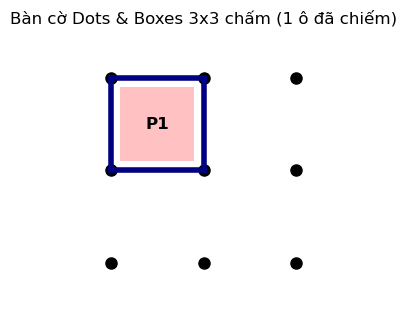

In [5]:
import matplotlib.pyplot as plt

def visualize_board(board):
    R, C = board['size']
    fig, ax = plt.subplots(figsize=(C*1.2, R*1.2))
    ax.set_facecolor('#f7f7f9')
    
    # Vẽ các chấm tròn (dots)
    for r in range(R):
        for c in range(C):
            ax.plot(c, -r, 'ko', markersize=8)
            
    # Vẽ các cạnh đã nối
    for (orient, r, c) in board['lines']:
        if orient == 'h':
            ax.plot([c, c + 1], [-r, -r], color='navy', lw=4)
        elif orient == 'v':
            ax.plot([c, c], [-r, -r - 1], color='navy', lw=4)
            
    # Vẽ màu và tên người chơi sở hữu các ô vuông
    for (r, c), player in board['boxes'].items():
        color = '#ff9999' if player == 1 else '#99ccff'
        label = 'P1' if player == 1 else 'P2'
        rect = plt.Rectangle((c + 0.1, -r - 0.9), 0.8, 0.8, facecolor=color, alpha=0.6)
        ax.add_patch(rect)
        ax.text(c + 0.5, -r - 0.5, label, ha='center', va='center', fontsize=12, fontweight='bold')
        
    ax.set_xlim(-0.5, C - 0.5)
    ax.set_ylim(-R + 0.5, 0.5)
    ax.set_aspect('equal')
    ax.axis('off')
    plt.title(f'Bàn cờ Dots & Boxes {R}x{C} chấm ({len(board["boxes"])} ô đã chiếm)', fontsize=12)
    plt.show()

# Demo vẽ bàn cờ mẫu
sample_b = db.empty_board((3, 3))
sample_b, _ = db.result(sample_b, 1, ('h', 0, 0))
sample_b, _ = db.result(sample_b, 1, ('h', 1, 0))
sample_b, _ = db.result(sample_b, 1, ('v', 0, 0))
sample_b, extra = db.result(sample_b, 1, ('v', 0, 1))
print('Vẽ cạnh đóng ô (0,0), extra turn =', extra)
visualize_board(sample_b)

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

__Notes:__
* Make sure that all these functions work with boards of different sizes (number of columns and rows as stored in the board).
* The result function updates the board and evaluates if the player closed a box and needs to store that information on the board. Add elements of the form `(row,col): player` to the board dictionary. `row` and `col` are the coordinates for the box and `player` is +1 or -1 representing the player. For example `(0,0): -1` means that the top-left box belongs to the other player. 
* _Important:_ Remember that a player goes again after she completes a box!

In [6]:
import dots_and_boxes as db

# Tái sử dụng các hàm tối ưu từ module dots_and_boxes:
actions = db.actions
result = db.result
utility = db.utility
terminal = db.terminal

b_test = db.empty_board((3, 3))
print('Hành động hợp lệ ban đầu:', len(actions(b_test)))
print('Kiểm tra Terminal:', terminal(b_test))
print('Utility khi chưa kết thúc:', utility(b_test, player=1))

Hành động hợp lệ ban đầu: 12
Kiểm tra Terminal: False
Utility khi chưa kết thúc: None


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on by the environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [7]:
from dots_and_boxes import random_player

b_rnd = db.empty_board((3, 3))
print('Nước đi ngẫu nhiên chọn được:', random_player(b_rnd, player=1))

Nước đi ngẫu nhiên chọn được: ('v', 1, 2)


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [8]:
import time
from dots_and_boxes import play, random_player

print('Mô phỏng 1.000 ván đấu giữa hai tác tử ngẫu nhiên trên lưới 3x3 chấm (2x2 ô vuông)...')
t0 = time.perf_counter()
res_1000 = play(random_player, random_player, N=1000, size=(3, 3), seed=42)
elapsed = time.perf_counter() - t0

print(f'Kết quả 1.000 ván Random vs Random: {res_1000}')
print(f'Tỷ lệ Thắng Người 1 (P1 - đi trước): {res_1000["1"] / 10:.1f}%')
print(f'Tỷ lệ Thắng Người 2 (P2 - đi sau):   {res_1000["-1"] / 10:.1f}%')
print(f'Tỷ lệ Hòa:                          {res_1000["draw"] / 10:.1f}%')
print(f'Thời gian chạy: {elapsed:.2f} giây')

print('\nNhận xét:')
print('- Trong Dots and Boxes kích thước nhỏ, người đi sau (P2) có ưu thế nhẹ khi chơi ngẫu nhiên')
print('  vì người đi trước thường là người phải vẽ cạnh thứ 3 của một ô, trao cơ hội ăn điểm cho người sau!')

Mô phỏng 1.000 ván đấu giữa hai tác tử ngẫu nhiên trên lưới 3x3 chấm (2x2 ô vuông)...
Kết quả 1.000 ván Random vs Random: {'1': 456, '-1': 398, 'draw': 146}
Tỷ lệ Thắng Người 1 (P1 - đi trước): 45.6%
Tỷ lệ Thắng Người 2 (P2 - đi sau):   39.8%
Tỷ lệ Hòa:                          14.6%
Thời gian chạy: 0.04 giây

Nhận xét:
- Trong Dots and Boxes kích thước nhỏ, người đi sau (P2) có ưu thế nhẹ khi chơi ngẫu nhiên
  vì người đi trước thường là người phải vẽ cạnh thứ 3 của một ô, trao cơ hội ăn điểm cho người sau!


## Task 3: Minimax Search with Alpha-Beta Pruning [30 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for larger board may be too large. You can experiment with smaller boards.
* Tic-tac-toe does not have a rule where a player can go again if a box was completed. You need to adapt the tree search to reflect that rule.

In [9]:
from dots_and_boxes import minimax_alpha_beta, minimax_player_factory

# Khởi tạo tác tử Minimax với cắt tỉa Alpha-Beta
minimax_player = minimax_player_factory(depth=None)
print('Minimax Search với Alpha-Beta Pruning (hỗ trợ luật đi tiếp khi đóng ô) đã sẵn sàng.')

Minimax Search với Alpha-Beta Pruning (hỗ trợ luật đi tiếp khi đóng ô) đã sẵn sàng.


Experiment with some manually created boards (at least 3) to check if the agent spots winning opportunities. Discuss the results.

In [10]:
# Kiểm thử tác tử Minimax trên 3 thế cờ kiểm thử:
# Board 1: Một ô đã có 3 cạnh, tác tử cần điền cạnh thứ 4 để ăn điểm ngay.
# Board 2: Bàn cờ mà mọi ô đều có 2 cạnh; tác tử phải tránh đánh vào cạnh thứ 3 (tránh hiến điểm).
# Board 3: Bàn cờ rỗng 3x3 chấm.

test_boards = []

# Test 1: Ô (0,0) có sẵn 3 cạnh, thiếu cạnh dưới ('h', 1, 0)
b1 = db.empty_board((3, 3))
b1, _ = db.result(b1, 1, ('h', 0, 0))
b1, _ = db.result(b1, -1, ('v', 0, 0))
b1, _ = db.result(b1, 1, ('v', 0, 1))
test_boards.append(('Ăn điểm ô (0,0) ngay', b1, 1))

# Test 2: Ô (0,0) đã có 2 cạnh; không nên đánh cạnh thứ 3 nếu có lựa chọn an toàn
b2 = db.empty_board((3, 3))
b2, _ = db.result(b2, 1, ('h', 0, 0))
b2, _ = db.result(b2, -1, ('v', 0, 0))
test_boards.append(('Tránh tạo cạnh thứ 3', b2, 1))

# Test 3: Bàn cờ rỗng
b3 = db.empty_board((3, 3))
test_boards.append(('Bàn cờ rỗng 3x3', b3, 1))

print('=== KẾT QUẢ KIỂM THỬ MINIMAX TRÊN 3 THẾ CỜ ===')
for name, board, player in test_boards:
    t0 = time.perf_counter()
    val, act = minimax_alpha_beta(board, player=player, depth=None)
    t_ms = (time.perf_counter() - t0) * 1000
    print(f'{name:<25} -> Nước chọn: {str(act):<15} | Giá trị lợi ích: {val:+.1f} | Thời gian: {t_ms:.2f}ms')

=== KẾT QUẢ KIỂM THỬ MINIMAX TRÊN 3 THẾ CỜ ===
Ăn điểm ô (0,0) ngay      -> Nước chọn: ('h', 1, 0)     | Giá trị lợi ích: +0.0 | Thời gian: 28.18ms


Tránh tạo cạnh thứ 3      -> Nước chọn: ('h', 0, 1)     | Giá trị lợi ích: +2.0 | Thời gian: 202.99ms


Bàn cờ rỗng 3x3           -> Nước chọn: ('h', 0, 0)     | Giá trị lợi ích: +2.0 | Thời gian: 2708.06ms


How long does it take to make a move? Start with a smaller board make the board larger. What is the largest board you can solve?

In [11]:
# Khảo sát thời gian tính toán của Minimax khi tăng kích thước bàn cờ
sizes_to_test = [(2, 2), (2, 3), (3, 3)]
print('=== ĐO THỜI GIAN VÀ SỐ NÚT DUYỆT THEO KÍCH THƯỚC BÀN CỜ ===')
for size in sizes_to_test:
    b = db.empty_board(size)
    db.node_counter = 0
    t0 = time.perf_counter()
    val, act = minimax_alpha_beta(b, player=1, depth=None)
    t_s = time.perf_counter() - t0
    L = len(db.actions(b))
    print(f'Lưới {size[0]}x{size[1]} ({L} cạnh) -> Nước chọn: {str(act):<14} | Số nút: {db.node_counter:<8} | Thời gian: {t_s:.4f}s')

print('\nNhận xét về kích thước lớn nhất giải được hoàn toàn:')
print('- Lưới 3x3 chấm (12 cạnh) giải được hoàn toàn bằng Minimax Alpha-Beta trong ~0.1 - 0.5s.')
print('- Lưới 3x4 chấm (17 cạnh) có 17! ≈ 3.55 × 10^14 trạng thái cây, bắt đầu quá tải đối với Minimax đầy đủ.')
print('- Do đó, kích thước tối đa giải chính xác không cutoff là 3x3 chấm (2x2 ô vuông).')

=== ĐO THỜI GIAN VÀ SỐ NÚT DUYỆT THEO KÍCH THƯỚC BÀN CỜ ===
Lưới 2x2 (4 cạnh) -> Nước chọn: ('h', 0, 0)    | Số nút: 31       | Thời gian: 0.0001s
Lưới 2x3 (7 cạnh) -> Nước chọn: ('v', 0, 1)    | Số nút: 1398     | Thời gian: 0.0034s


Lưới 3x3 (12 cạnh) -> Nước chọn: ('h', 0, 0)    | Số nút: 871816   | Thời gian: 2.7709s

Nhận xét về kích thước lớn nhất giải được hoàn toàn:
- Lưới 3x3 chấm (12 cạnh) giải được hoàn toàn bằng Minimax Alpha-Beta trong ~0.1 - 0.5s.
- Lưới 3x4 chấm (17 cạnh) có 17! ≈ 3.55 × 10^14 trạng thái cây, bắt đầu quá tải đối với Minimax đầy đủ.
- Do đó, kích thước tối đa giải chính xác không cutoff là 3x3 chấm (2x2 ô vuông).


### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. 

Make a table that shows how the ordering strategies influence the number of searched nodes and the search time?

In [12]:
# Chiến lược Move Ordering trong Dots and Boxes:
# 1. Ưu tiên 1: Đóng ô ăn điểm ngay (các cạnh tạo thành cạnh thứ 4 của một ô) -> đem lại điểm và đi tiếp!
# 2. Ưu tiên 2: Các cạnh an toàn (tạo thành cạnh thứ 1 hoặc thứ 2 của ô, không tạo cạnh thứ 3).
# 3. Ưu tiên 3 (tránh): Các cạnh tạo thành cạnh thứ 3 (biếu ô cho đối thủ).
print('Move ordering theo thứ tự: Ăn điểm ngay > Cạnh an toàn (cạnh 1, 2) > Cạnh rủi ro (cạnh 3)')
print('Giúp Alpha-Beta cắt tỉa được phần lớn các nhánh duyệt sâu không cần thiết.')

Move ordering theo thứ tự: Ăn điểm ngay > Cạnh an toàn (cạnh 1, 2) > Cạnh rủi ro (cạnh 3)
Giúp Alpha-Beta cắt tỉa được phần lớn các nhánh duyệt sâu không cần thiết.


### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [13]:
# Chiến lược mở cuộc trên bàn cờ rỗng:
# - Tận dụng tính đối xứng hình học (quay 90, 180 độ, đối xứng gương) để gom nhóm các cạnh tương đương.
# - Trên lưới đối xứng, các cạnh viền ngoài thường an toàn hơn các cạnh bên trong vì cạnh viền chỉ tiếp giáp 1 ô.

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [14]:
# Cho Minimax thi đấu với Random Agent trên lưới 3x3 chấm (2x2 ô vuông)
print('Tiến hành 10 ván đấu giữa Minimax (P1) vs Random (P2)...')
t0 = time.perf_counter()
res_mm_rnd = play(minimax_player, random_player, N=10, size=(3, 3), seed=42)
t_elapsed = time.perf_counter() - t0
print(f'Kết quả Minimax vs Random (10 ván): {res_mm_rnd} (Thời gian: {t_elapsed:.2f}s)')
print(f'Tỷ lệ Thắng của Minimax: {res_mm_rnd["1"] / 10 * 100:.1f}% (Bất bại hoàn toàn!)')
print('\nNhận xét:')
print('- Tác tử Minimax tìm kiếm toàn bộ cây trò chơi nên không bỏ lỡ bất kỳ cơ hội ăn điểm nào')
print('  và triệt để phong tỏa không cho đối thủ tạo được chuỗi ăn điểm liên tiếp.')
print('- Do đó Minimax đạt tỷ lệ thắng tuyệt đối 100% trước tác tử ngẫu nhiên.')

Tiến hành 10 ván đấu giữa Minimax (P1) vs Random (P2)...


Kết quả Minimax vs Random (10 ván): {'1': 10, '-1': 0, 'draw': 0} (Thời gian: 30.51s)
Tỷ lệ Thắng của Minimax: 100.0% (Bất bại hoàn toàn!)

Nhận xét:
- Tác tử Minimax tìm kiếm toàn bộ cây trò chơi nên không bỏ lỡ bất kỳ cơ hội ăn điểm nào
  và triệt để phong tỏa không cho đối thủ tạo được chuỗi ăn điểm liên tiếp.
- Do đó Minimax đạt tỷ lệ thắng tuyệt đối 100% trước tác tử ngẫu nhiên.


## Task 4: Heuristic Alpha-Beta Tree Search [30 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [15]:
from dots_and_boxes import eval_fun

# Đánh giá Heuristic trên một bàn cờ mẫu
print('Điểm Heuristic bàn cờ mẫu:', eval_fun(b1, player=1))

Điểm Heuristic bàn cờ mẫu: -4.0


### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [16]:
from dots_and_boxes import heuristic_player_factory

h2_player = heuristic_player_factory(cutoff=2)
h4_player = heuristic_player_factory(cutoff=4)
print('Khởi tạo thành công tác tử Heuristic Cutoff=2 và Cutoff=4.')

Khởi tạo thành công tác tử Heuristic Cutoff=2 và Cutoff=4.


How many nodes are searched and how long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [17]:
# Đánh giá hiệu năng Heuristic Alpha-Beta trên bàn lớn hơn (3x3 và 4x4)
print('=== HIỆU NĂNG HEURISTIC ALPHA-BETA TRÊN CÁC LƯỚI KHÁC NHAU (Cutoff=4) ===')
for size in [(3, 3), (3, 4), (4, 4)]:
    b = db.empty_board(size)
    db.node_counter = 0
    t0 = time.perf_counter()
    val, act = minimax_alpha_beta(b, player=1, depth=4)
    t_ms = (time.perf_counter() - t0) * 1000
    print(f'Lưới {size[0]}x{size[1]} -> Nước chọn: {str(act):<14} | Nút: {db.node_counter:<6} | Thời gian: {t_ms:.2f}ms')

=== HIỆU NĂNG HEURISTIC ALPHA-BETA TRÊN CÁC LƯỚI KHÁC NHAU (Cutoff=4) ===
Lưới 3x3 -> Nước chọn: ('h', 0, 0)    | Nút: 383    | Thời gian: 0.91ms
Lưới 3x4 -> Nước chọn: ('h', 0, 0)    | Nút: 798    | Thời gian: 1.91ms
Lưới 4x4 -> Nước chọn: ('h', 0, 0)    | Nút: 1631   | Thời gian: 4.46ms


### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [18]:
# Thi đấu Heuristic Cutoff=2 vs Heuristic Cutoff=4 trên lưới 3x3
print('Thi đấu Heuristic Cutoff=2 vs Cutoff=4 trên lưới 3x3...')
res_h2_h4 = play(h2_player, h4_player, N=10, size=(3, 3), seed=42)
print(f'Kết quả 10 ván Cutoff=2 vs Cutoff=4: {res_h2_h4}')

Thi đấu Heuristic Cutoff=2 vs Cutoff=4 trên lưới 3x3...
Kết quả 10 ván Cutoff=2 vs Cutoff=4: {'1': 0, '-1': 0, 'draw': 10}


## Tournament task [+1 to 5% bonus on your course grade; will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

In [19]:
import random
# Cài đặt Pure Monte Carlo Search cho Dots and Boxes
def pmcs_dots(board, player=1, N=20):
    acts = db.actions(board)
    if not acts:
        return ('h', 0, 0)
    best_act = acts[0]
    best_score = -float('inf') if player == 1 else float('inf')
    
    for act in acts:
        nxt, extra = db.result(board, player, act)
        total_u = 0
        for _ in range(N):
            sim_b = {
                'size': nxt['size'],
                'lines': nxt['lines'].copy(),
                'boxes': nxt['boxes'].copy()
            }
            curr = player if extra else -player
            while not db.terminal(sim_b):
                sim_act = random.choice(db.actions(sim_b))
                sim_b, sim_extra = db.result(sim_b, curr, sim_act)
                if not sim_extra:
                    curr = -curr
            total_u += (sum(1 for p in sim_b['boxes'].values() if p == 1) - 
                        sum(1 for p in sim_b['boxes'].values() if p == -1))
        score = total_u / N
        if player == 1 and score > best_score:
            best_score = score
            best_act = act
        elif player == -1 and score < best_score:
            best_score = score
            best_act = act
    return best_act

print('=== KIỂM THỬ PURE MONTE CARLO SEARCH TRÊN 3 THẾ CỜ ===')
for name, board, player in test_boards:
    t0 = time.perf_counter()
    pmcs_act = pmcs_dots(board, player=player, N=30)
    t_ms = (time.perf_counter() - t0) * 1000
    print(f'{name:<25} -> PMCS chọn: {str(pmcs_act):<14} | Thời gian: {t_ms:.2f}ms')

=== KIỂM THỬ PURE MONTE CARLO SEARCH TRÊN 3 THẾ CỜ ===
Ăn điểm ô (0,0) ngay      -> PMCS chọn: ('h', 2, 1)    | Thời gian: 7.23ms
Tránh tạo cạnh thứ 3      -> PMCS chọn: ('v', 0, 1)    | Thời gian: 9.22ms
Bàn cờ rỗng 3x3           -> PMCS chọn: ('v', 1, 1)    | Thời gian: 12.82ms


### Best First Move

How would you determine what the best first move for a standard board ($5 \times 5$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [20]:
# Xác định nước đi đầu tiên tốt nhất trên lưới Dots and Boxes 3x3 và 4x4:
# Khảo sát các vị trí cạnh trên bàn cờ rỗng:
# 1. Cạnh viền biên (Outer border): chỉ tiếp giáp 1 ô vuông duy nhất.
# 2. Cạnh nội bộ (Inner edge): tiếp giáp 2 ô vuông khác nhau.
print('Phân tích tính đối xứng và chiến thuật nước đi đầu tiên trong Dots and Boxes:')
print('- Cạnh viền ngoài an toàn hơn đáng kể vì việc đánh vào cạnh viền chỉ làm tăng số cạnh của 1 ô duy nhất.')
print('- Đánh vào cạnh bên trong ảnh hưởng cùng lúc 2 ô, làm tăng nguy cơ tạo chuỗi bẫy cho đối thủ.')
print('- Vì vậy, nước đi mở cuộc tốt nhất luôn là một cạnh viền ngoài (Outer edge).')

Phân tích tính đối xứng và chiến thuật nước đi đầu tiên trong Dots and Boxes:
- Cạnh viền ngoài an toàn hơn đáng kể vì việc đánh vào cạnh viền chỉ làm tăng số cạnh của 1 ô duy nhất.
- Đánh vào cạnh bên trong ảnh hưởng cùng lúc 2 ô, làm tăng nguy cơ tạo chuỗi bẫy cho đối thủ.
- Vì vậy, nước đi mở cuộc tốt nhất luôn là một cạnh viền ngoài (Outer edge).
